In [9]:
# im_Dyskeratotic
# 009_01.bmp
# 012_01.bmp
# ---------------------
#im_Koilocytotic
# 134_04.bmp
# 141_05.bmp
# ---------------------
#im_Metaplastic
# 168_01.bmp
# 205_03.bmp
# ------------------------
# im_Parabasal
# 097_12.bmp
#090_01.bmp
# -----------------------
# im_Superficial-Intermediate
# 001_02.bmp
# 001_05.bmp


# **Architecture Viewer**

Traceback (most recent call last):
  File "d:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\scripts\architecture_diagram.py", line 160, in <module>
    main()
  File "d:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\scripts\architecture_diagram.py", line 151, in main
    image = Image.open(IMAGE).convert("RGB")
  File "c:\Users\Manuel\anaconda3\envs\cervifusion\lib\site-packages\PIL\Image.py", line 3465, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'D:\\ExcellencProject\\2026\\CervicalFusion\\CervicalFusion-20261112T164414Z-1-001\\CervicalFusion\\archive\\im_Dyskeratotic\\im_Dyskeratotic\\CROPPED\\007_01.bmp'


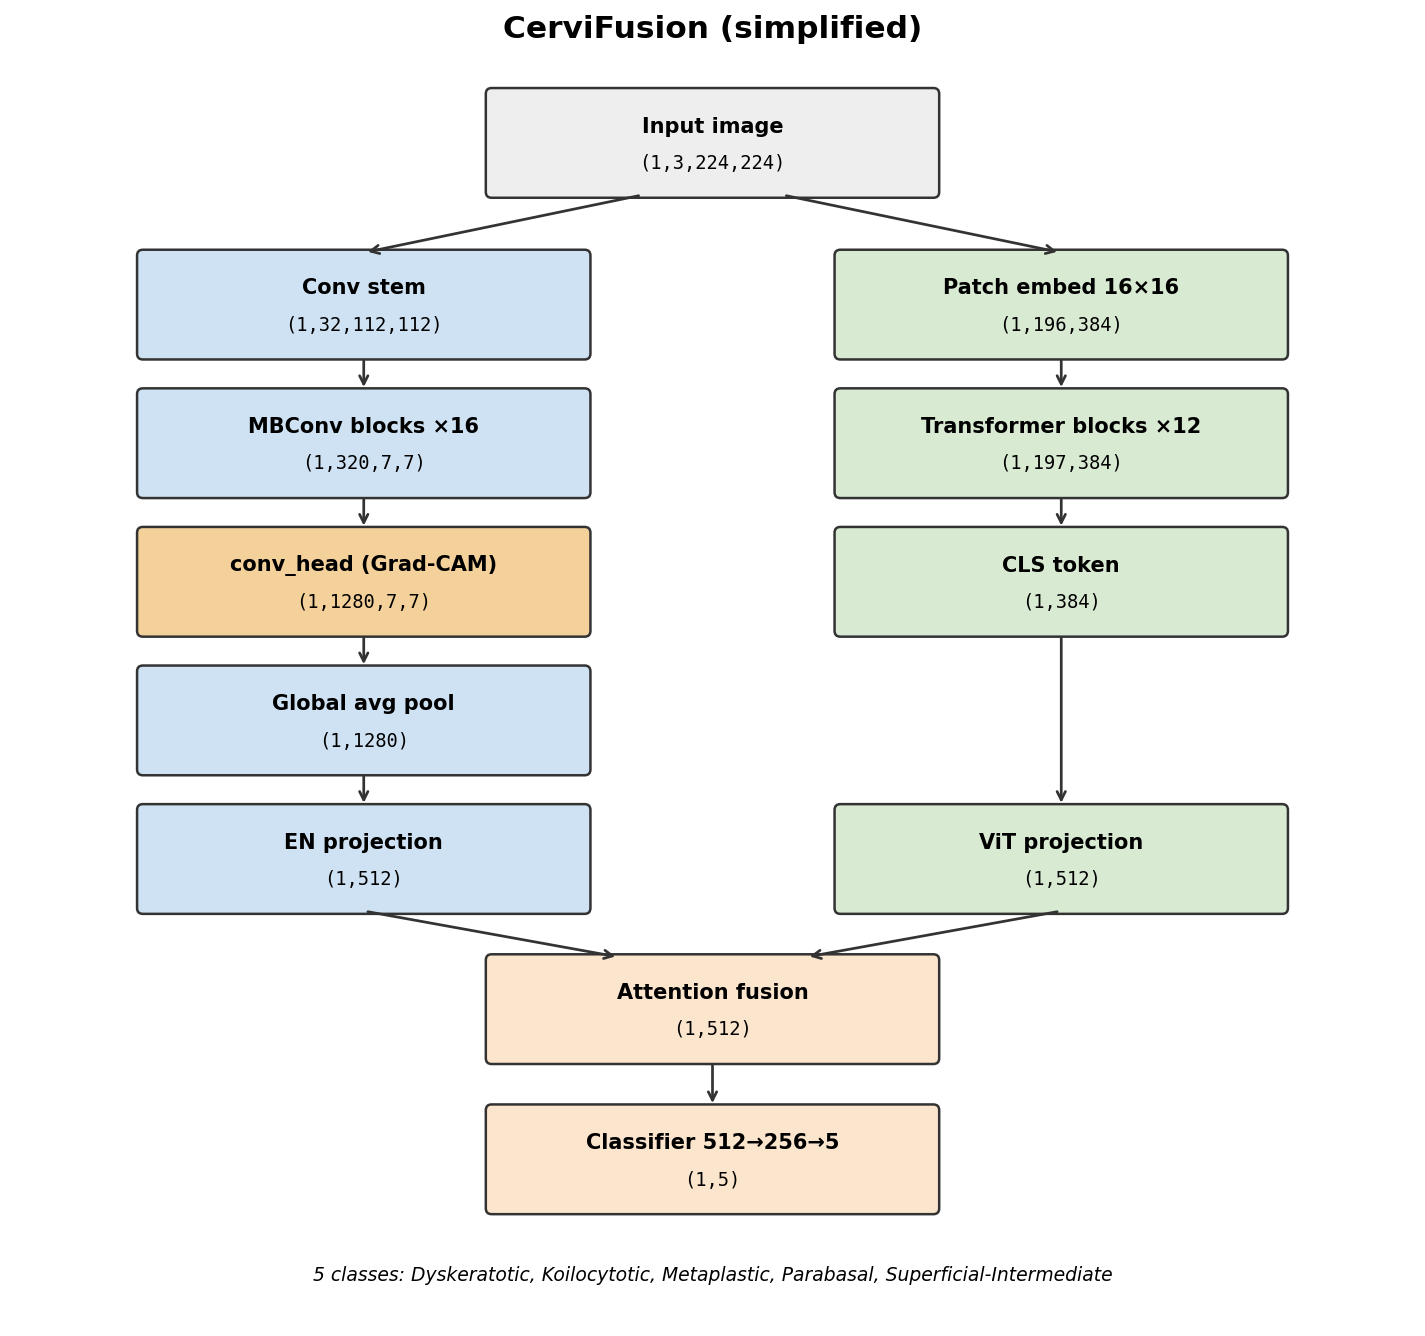

In [1]:
from pathlib import Path
from IPython.display import display
from PIL import Image

!python scripts/architecture_diagram.py

image_path = Path.cwd() / "results" / "architecture" / "cervifusion_simplified.png"
display(Image.open(image_path))

Device: cpu
Checkpoint: D:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\checkpoints\cervifusion\best_model.pt
Loaded epoch 14 | val acc 0.9766 | size=224
Grad-CAM: layer=head, method=gradcam, grad=full, resize=stretch
Image: d:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\dataset\main\im_Superficial-Intermediate\im_Superficial-Intermediate\CROPPED\001_05.bmp
Prediction: Superficial-Intermediate (0.9960)
Grad-CAM grid: 7x7 upsampled to 224x224
Saved: D:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\results\explainability\gradcam.png
Figure(1400x450)
Input: d:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\dataset\main\im_Superficial-Intermediate\im_Superficial-Intermediate\CROPPED\001_05.bmp
Grad-CAM: d:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\results\explainabili

d:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\scripts\05_grad_cam.py:281: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt =

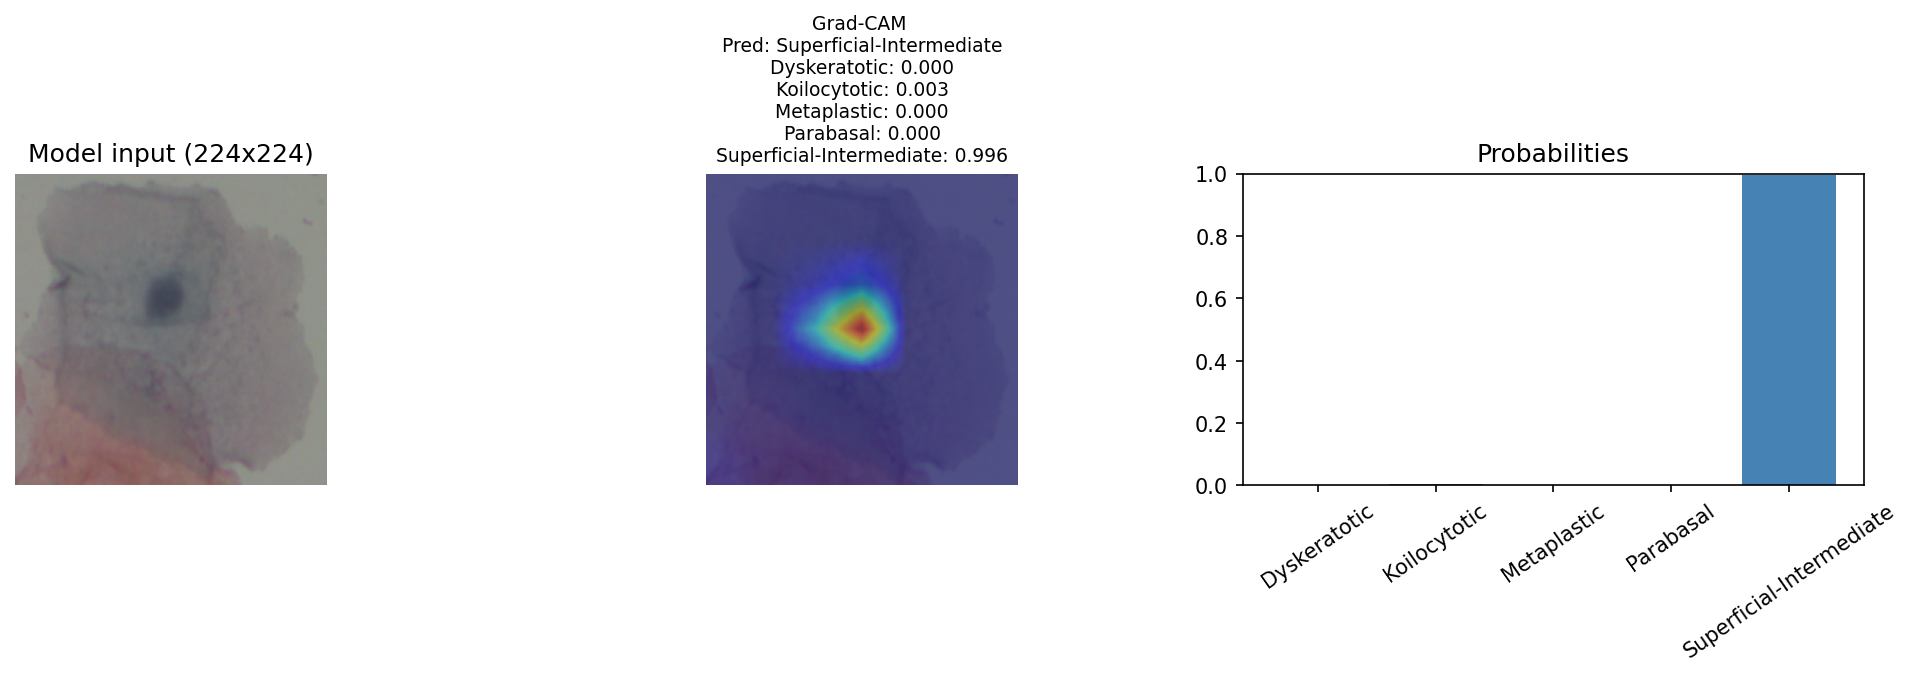

In [6]:
from pathlib import Path
from IPython.display import display
from PIL import Image

PROJECT_ROOT = Path.cwd()
INPUT_IMAGE = (
    PROJECT_ROOT
    / "dataset"
    / "main"
    / "im_Superficial-Intermediate"
    / "im_Superficial-Intermediate"
    / "CROPPED"
    / "001_05.bmp"
)

!python scripts/05_grad_cam.py --image "{INPUT_IMAGE}" --show

OUTPUT_IMAGE = PROJECT_ROOT / "results" / "explainability" / "gradcam.png"

print("Input:", INPUT_IMAGE)
print("Grad-CAM:", OUTPUT_IMAGE)

display(Image.open(OUTPUT_IMAGE))

In [4]:
!pip install -q gradio

In [5]:
import gradio as gr
from pathlib import Path
from PIL import Image
import subprocess
import shutil

# Project folder
PROJECT_ROOT = Path.cwd()

# Grad-CAM output
OUTPUT_IMAGE = PROJECT_ROOT / "results" / "explainability" / "gradcam.png"


def run_gradcam(input_image):
    if input_image is None:
        return None, None, "Please upload an image."

    # Run your existing Grad-CAM script
    command = [
        "python",
        str(PROJECT_ROOT / "scripts" / "05_grad_cam.py"),
        "--image",
        input_image,
        "--show"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    # If script failed
    if result.returncode != 0:
        return None, None, result.stderr

    # Check whether output exists
    if not OUTPUT_IMAGE.exists():
        return None, None, "Grad-CAM output image was not generated."

    return input_image, str(OUTPUT_IMAGE), result.stdout


# UI
with gr.Blocks(title="CervicalFusion Grad-CAM") as demo:

    gr.Markdown("# CervicalFusion — Grad-CAM")
    gr.Markdown("Upload a cervical image and generate the Grad-CAM visualization.")

    with gr.Row():

        input_image = gr.Image(
            type="filepath",
            label="Input Image"
        )

        output_image = gr.Image(
            type="filepath",
            label="Grad-CAM Output"
        )

    run_button = gr.Button(
        "🔥 Run Grad-CAM",
        variant="primary"
    )

    logs = gr.Textbox(
        label="Output / Logs",
        lines=8
    )

    run_button.click(
        fn=run_gradcam,
        inputs=input_image,
        outputs=[input_image, output_image, logs]
    )


demo.launch(share=True)

c:\Users\Manuel\anaconda3\envs\cervifusion\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/11/13 11:55:09 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: i/o timeout
